# EDA development: Tái nhập viện sớm
Chỉ dùng development để tìm hiểu dữ liệu. Không chọn feature/model bằng test.

In [1]:
from pathlib import Path
import sys
root = Path.cwd()
if not (root / "src").exists(): root = root.parent
sys.path.insert(0, str(root / "src"))
import pandas as pd, numpy as np
from IPython.display import display, Image, Markdown
from healthcare_ml.data import load_dataset, feature_columns


In [2]:
df, split = load_dataset("readmission")
dev = df.iloc[split["development"]]
display(dev[feature_columns(df,"readmission")].head())
display(dev.y.value_counts().rename("count"))
display(dev[feature_columns(df,"readmission")].isna().mean().sort_values(ascending=False).head(15))

,race,gender,age,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,...,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed
1,Caucasian,Female,[10-20),1,1,7,3,59,0,18,...,No,No,Up,No,No,No,No,No,Ch,Yes
2,AfricanAmerican,Female,[20-30),1,1,7,2,11,5,13,...,No,No,No,No,No,No,No,No,No,Yes
3,Caucasian,Male,[30-40),1,1,7,2,44,1,16,...,No,No,Up,No,No,No,No,No,Ch,Yes
5,Caucasian,Male,[50-60),2,1,2,3,31,6,16,...,No,No,Steady,No,No,No,No,No,No,Yes
6,Caucasian,Male,[60-70),3,1,2,4,70,1,21,...,No,No,Steady,No,No,No,No,No,Ch,Yes


y
0    70314
1     8995
Name: count, dtype: int64

race             0.022482
diag_3           0.014689
diag_2           0.003619
diag_1           0.000214
troglitazone     0.000000
glyburide        0.000000
tolbutamide      0.000000
pioglitazone     0.000000
rosiglitazone    0.000000
acarbose         0.000000
miglitol         0.000000
tolazamide       0.000000
acetohexamide    0.000000
examide          0.000000
citoglipton      0.000000
dtype: float64

## Phân phối, missingness và các câu hỏi
So sánh theo nhãn chỉ là liên hệ thống kê. Giữ `None` xét nghiệm như một trạng thái; mọi imputer/encoder học riêng trong train-fold.

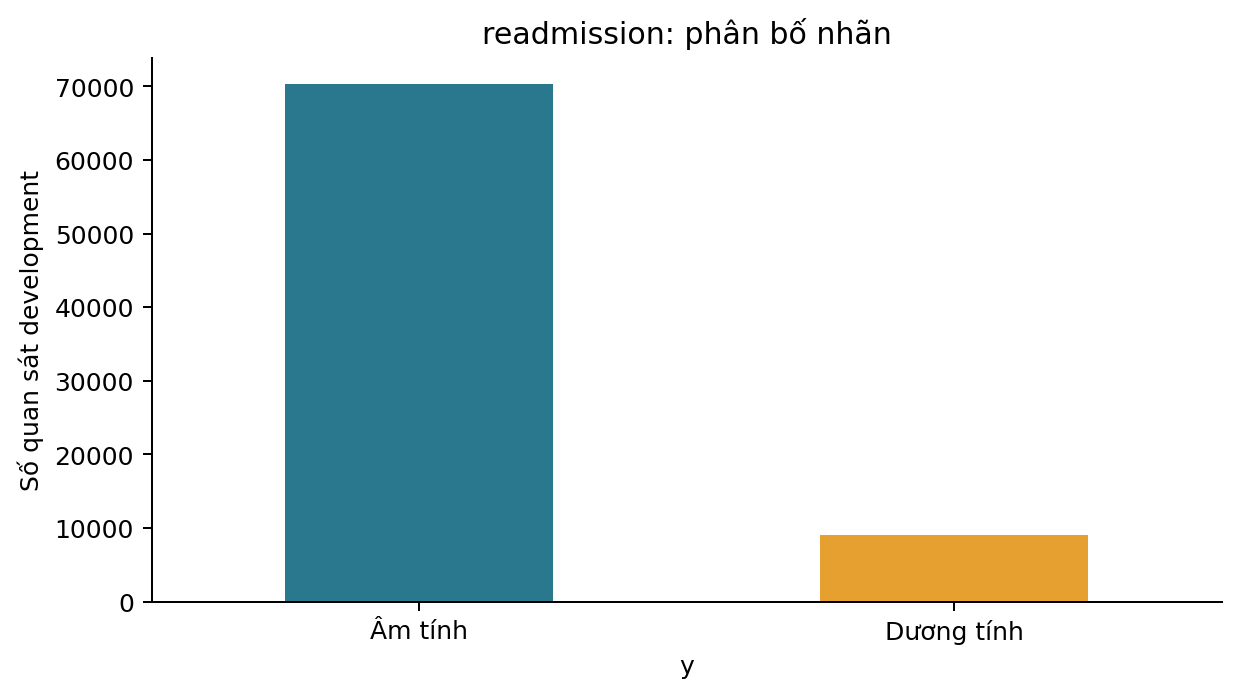

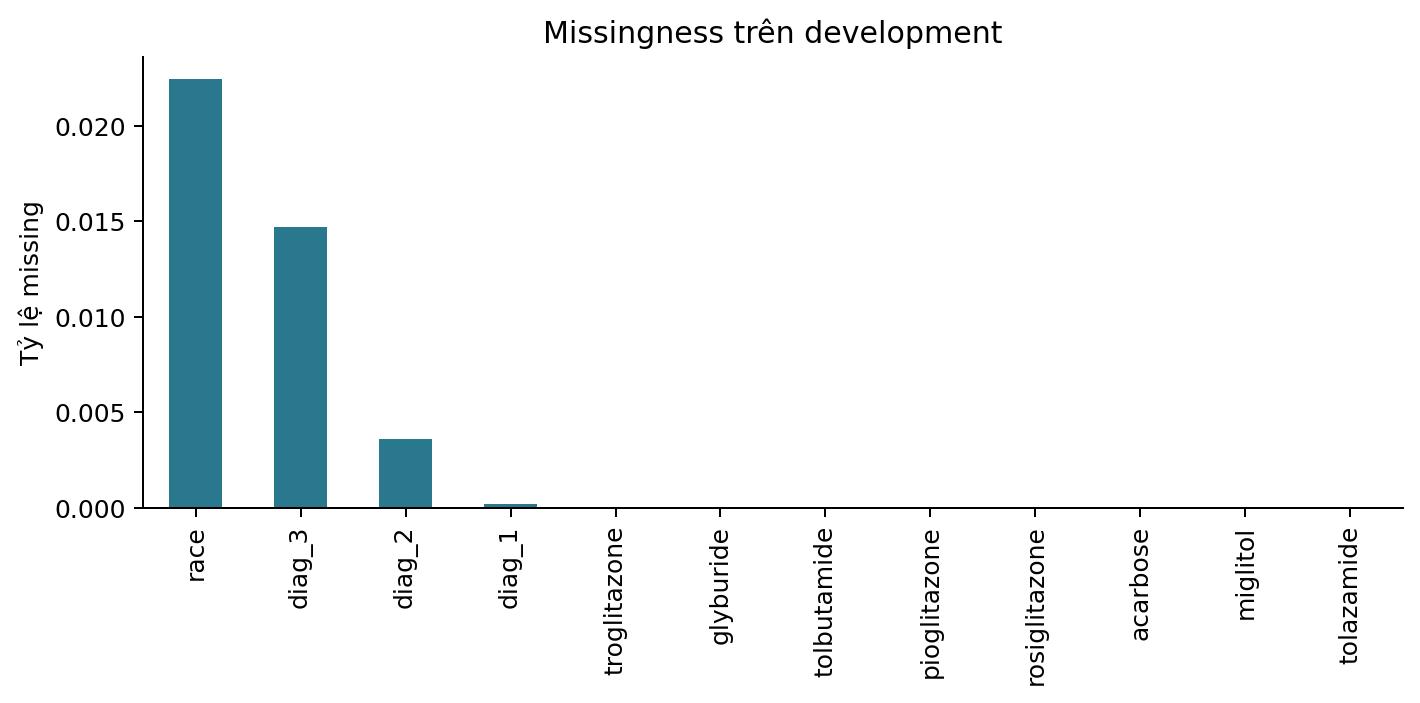

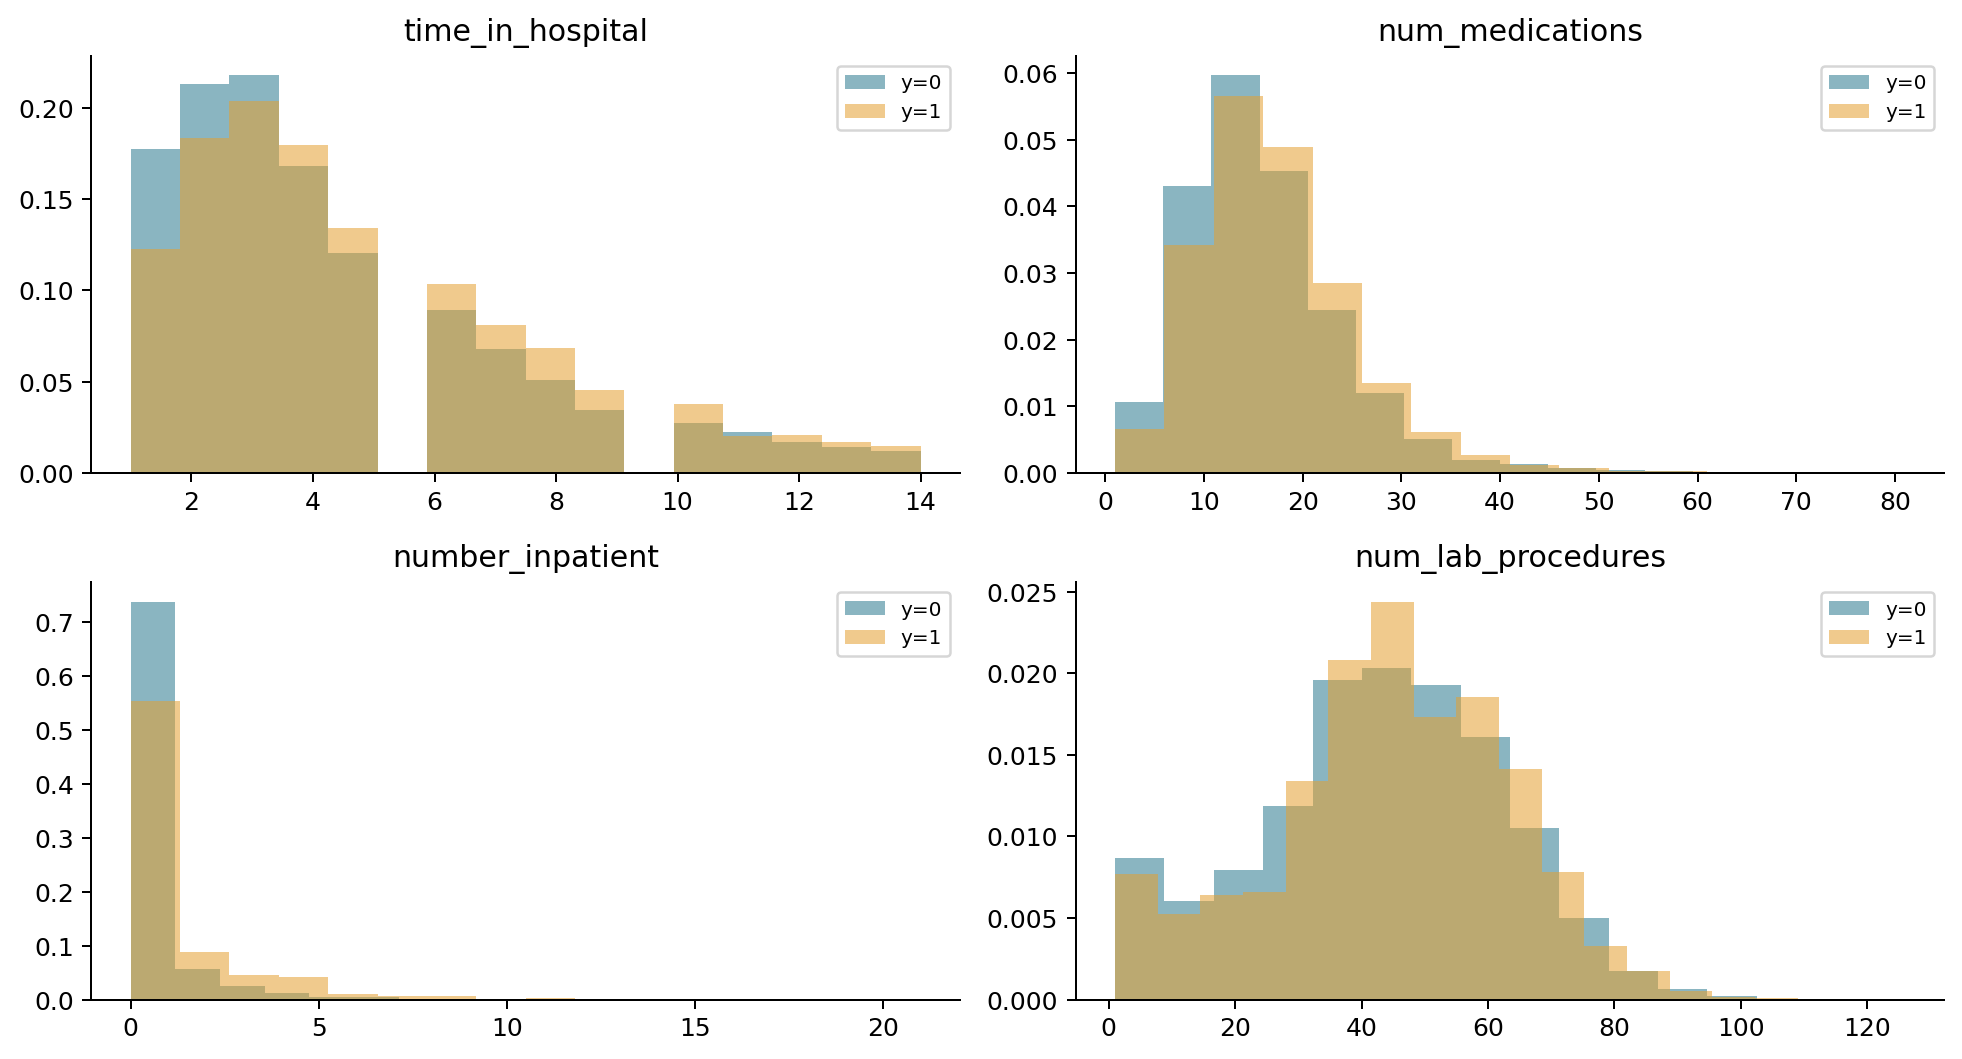

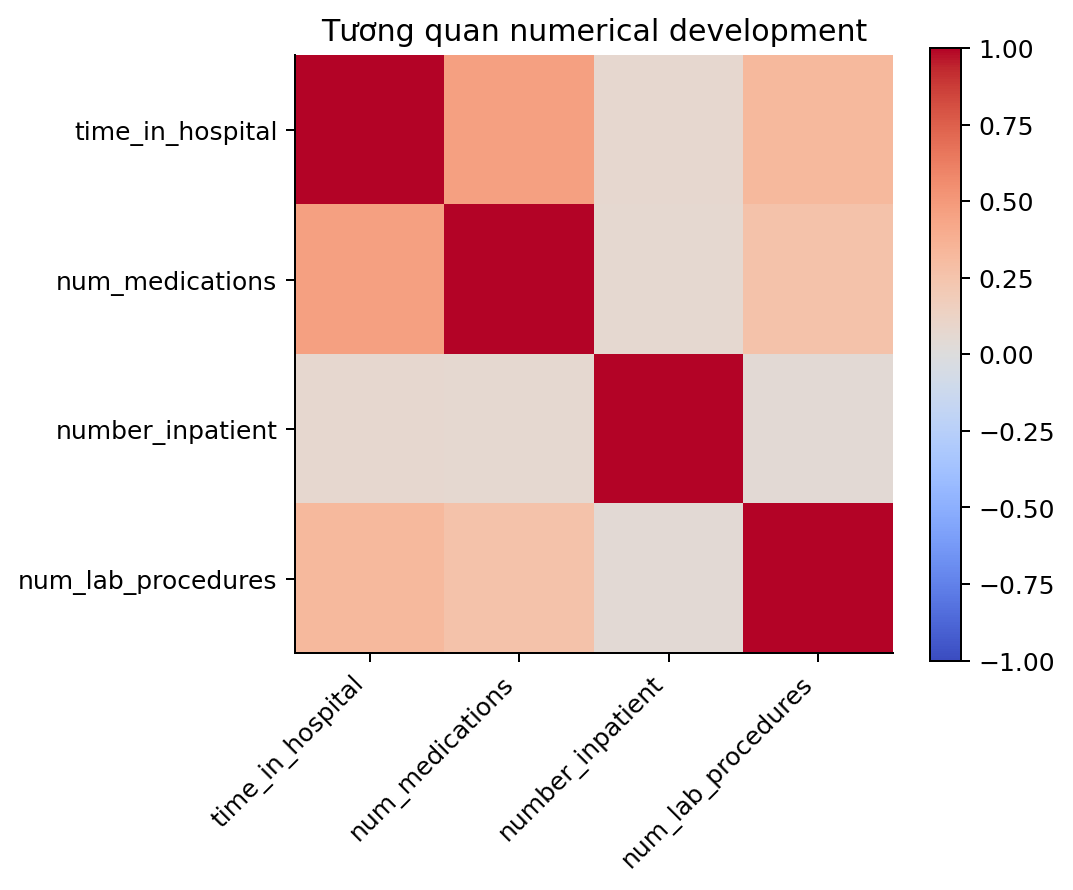

In [3]:
for suffix in ["labels", "missing", "distributions", "correlation"]:
    display(Image(filename=str(root / "artifacts/figures" / f"readmission_{suffix}.png")))

## Split kiểm toán
Tập test giữ riêng; group patient tách biệt. Fit, calibration, threshold và test không giao nhau.

In [4]:
parts = ["fit", "calibration", "threshold", "test"]
for i,a in enumerate(parts):
    for b in parts[i+1:]:
        assert not set(df.iloc[split[a]].patient_nbr) & set(df.iloc[split[b]].patient_nbr)
print("Verified disjoint groups", {k:len(split[k]) for k in parts})

Verified disjoint groups {'fit': 59372, 'calibration': 10083, 'threshold': 9854, 'test': 20031}
